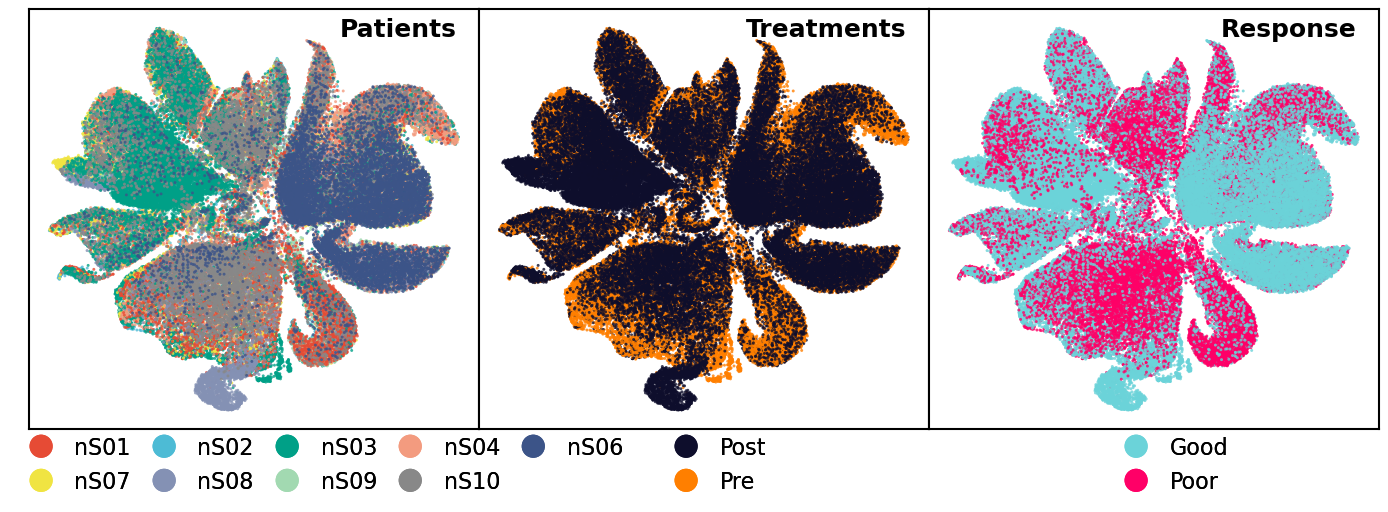

In [2]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import scanpy as sc
import math
# 1. Import modules required for custom legend handlers
from matplotlib.legend_handler import HandlerPatch

# ==========================================
# 1. Preprocessing and centralized color scheme definition
# ==========================================

# Define the custom circle legend handler class
class HandlerCircle(HandlerPatch):
    def create_artists(self, legend, orig_handle, xdescent, ydescent, width, height, fontsize, trans):
        # Calculate the center position of the circle
        center = 0.5 * width - 0.5 * xdescent, 0.5 * height - 0.5 * ydescent
        # Create a circle patch with a diameter equal to the legend row height
        p = mpatches.Circle(xy=center, radius=0.7*height)
        self.update_prop(p, orig_handle, legend)
        p.set_transform(trans)
        return [p]

p2e = {
    "nS01":"Poor",
    "nS02":"Poor",
    "nS09":"Poor",
    "nS10":"Poor"
}

adata_sc = sc.read("../h5ad/adata_sc.h5ad")
adata_sc.obs["patient"] = [b.split("-")[1] for b in adata_sc.obs["batch"]]
adata_sc.obs["time"] = ["Pre" if b.split("-")[0]=="Q" else "Post" for b in adata_sc.obs["batch"]]
adata_sc.obs["effect"] = [p2e.get(b.split("-")[1],"Good") for b in adata_sc.obs["batch"]]

# Group 1: Patients
patient_colors = [
    '#E64B35', '#4DBBD5', '#00A087', '#F39B7F', '#3C5488', 
    '#F0E442', '#8491B4', '#A2D9B1', '#888888'
]

# Group 2: Treatments
treatment_colors = [
    '#0E0E2C', '#FF7F00'
]

# Group 3: Response
response_colors = [
    '#6BD3D9', '#FF0067'
]

# Pack the three groups of colors for easy loop calls
all_custom_colors = [patient_colors, treatment_colors, response_colors]

# Forcefully modify the underlying colors of 'time' in adata_sc
adata_sc.uns['time_colors'] = treatment_colors

# ==========================================
# 2. Canvas setup and plotting
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(15, 7))

plot_configs = [
    {"key": "patient", "title": "Patients"},
    {"key": "time", "title": "Treatments"},
    {"key": "effect", "title": "Response"}
]

# Create three empty lists in advance to store legend handles and labels for the three groups of plots
group_handles = [[], [], []]
group_labels = [[], [], []]

for i, config in enumerate(plot_configs):
    key = config["key"]
    title = config["title"]

    # --- Core modification: Sync custom colors to adata_sc to force UMAP scatter colors ---
    custom_colors = all_custom_colors[i]
    categories = adata_sc.obs[key].astype('category').cat.categories
    # Ensure there are enough colors
    if len(custom_colors) < len(categories):
        extended_colors = custom_colors * (len(categories) // len(custom_colors) + 1)
    else:
        extended_colors = custom_colors
    # Write the color scheme into uns; the key must be "{group_column_name}_colors"
    adata_sc.uns[f"{key}_colors"] = extended_colors[:len(categories)]

    # --- Plotting (the scatter points will automatically read the colors just written) ---
    sc.pl.umap(
        adata_sc,
        color=key,
        size=18,
        alpha=0.8,
        ax=axes[i],
        show=False,
        legend_loc=None,
        frameon=False,
        title=""
    )

    # --- Post-processing border fix ---
    axes[i].axis('on') 
    for spine in axes[i].spines.values():
        spine.set_visible(True)
        spine.set_color('black')
        spine.set_linewidth(1.5)
    axes[i].set_xticks([])
    axes[i].set_yticks([])
    axes[i].set_xlabel('')
    axes[i].set_ylabel('')

    # --- Title: positioned at the top right corner ---
    axes[i].text(0.95, 0.98, title, 
             transform=axes[i].transAxes, 
             fontsize=18,
             ha='right',      
             va='top',        
             fontweight='bold')
    
    # --- Collect legend information ---
    for idx, cat in enumerate(categories):
        color = extended_colors[idx]
        patch = mpatches.Patch(color=color, label=cat)
        group_handles[i].append(patch)
        group_labels[i].append(cat)

# ==========================================
# 3. Layout adjustment and grouped legend generation
# ==========================================
plt.subplots_adjust(left=0.05, right=0.95, top=0.85, bottom=0.25, wspace=0)

# Define the positions of the three groups of legends on the canvas [left, bottom, width, height]
pos_p = [0.03, 0.13, 0.40, 0.15]  
pos_t = [0.46, 0.13, 0.40, 0.15]  
pos_e = [0.76, 0.13, 0.40, 0.15]  

# Core function: Rearrange the list to achieve a "two rows, multiple columns" visual effect
def arrange_in_two_rows(handles, labels):
    total = len(handles)
    n_cols = math.ceil(total / 2)
    
    # Pad the list length (if the total is odd, add an empty slot)
    if total % 2 != 0:
        handles = handles + [None]
        labels = labels + [""]
        
    # Split the list into two halves (i.e., two rows)
    first_row_h = handles[:n_cols]
    second_row_h = handles[n_cols:]
    first_row_l = labels[:n_cols]
    second_row_l = labels[n_cols:]
    
    # Interleaved merge
    new_handles = []
    new_labels = []
    for i in range(n_cols):
        new_handles.append(first_row_h[i])
        new_labels.append(first_row_l[i])
        if i < len(second_row_h) and second_row_h[i] is not None:
            new_handles.append(second_row_h[i])
            new_labels.append(second_row_l[i])
            
    return new_handles, new_labels, n_cols

# Transpose the data for the three groups separately
h_p, l_p, ncol_p = arrange_in_two_rows(group_handles[0], group_labels[0])
h_t, l_t, ncol_t = arrange_in_two_rows(group_handles[1], group_labels[1])
h_e, l_e, ncol_e = arrange_in_two_rows(group_handles[2], group_labels[2])

# 2. Create three independent legends respectively, and use handler_map={mpatches.Patch: HandlerCircle()} to map squares to circles
leg1 = fig.legend(h_p, l_p, loc='lower left', 
                  bbox_to_anchor=pos_p, ncol=ncol_p, frameon=False, fontsize=16, 
                  columnspacing=0.5, handletextpad=0.5, handler_map={mpatches.Patch: HandlerCircle()})
leg2 = fig.legend(h_t, l_t, loc='lower left', 
                  bbox_to_anchor=pos_t, ncol=ncol_t, frameon=False, fontsize=16, 
                  columnspacing=0.5, handletextpad=0.5, handler_map={mpatches.Patch: HandlerCircle()})
leg3 = fig.legend(h_e, l_e, loc='lower left', 
                  bbox_to_anchor=pos_e, ncol=ncol_e, frameon=False, fontsize=16, 
                  columnspacing=0.5, handletextpad=0.5, handler_map={mpatches.Patch: HandlerCircle()})

# Manually add all three legends back to the canvas
fig.add_artist(leg1)
fig.add_artist(leg2)
fig.add_artist(leg3)
plt.show()